In [1]:
from das_functions import *
from das_functions import get_tidal_info, get_weather_info
import os
import h5py
import numpy as np
import scipy.signal as signal
from scipy.signal import butter, filtfilt, detrend, hilbert, decimate, stft
from scipy.signal.windows import tukey
from matplotlib.colors import LogNorm
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from pyproj import Proj
from scipy.fft import fft2, fftfreq, fftshift, ifft2, ifftshift
from scipy.ndimage import gaussian_filter
from scipy.signal import hilbert
import scipy as sp
import roseus.mpl as rs
from scipy.signal import resample
from IPython.display import Audio
import glob
from scipy.signal import stft, istft, resample
from scipy.io.wavfile import write
import librosa
import matplotlib.colors as mcolors
import matplotlib.colors as mcolors
from scipy.ndimage import gaussian_filter, binary_dilation
import matplotlib.ticker as ticker
from matplotlib.colors import PowerNorm
from scipy.signal import welch

%matplotlib inline

%load_ext autoreload
%autoreload 2



## fk filter

In [3]:
##currents
##max
# Date         | Max Speed (m/s) | Occurred at (UTC)
# -------------------------------------------------------
# 2025-11-14   | 0.504206        | 04:00:00
# 2026-01-02   | 1.004708        | 05:00:00
# 2026-01-23   | 0.632121        | 10:00:00

# │ Date         | Min Speed (m/s) | Occurred at (UTC)                                                              
# │ -------------------------------------------------------                                                          │
# │ 2025-11-14   | 0.057056        | 13:00:00                                                                        │
# │ 2026-01-02   | 0.043018        | 23:00:00                                                                        │
# │ 2026-01-23   | 0.002050        | 16:00:00   


In [4]:
#fdir = "/mnt/nas_das4orcas_onyx/haro-nbg/" 
#fdir = "/mnt/nas_das4orcas_onyx/haro-fs/" 
# fdir = "/mnt/haro_fs/" 
#fdir = "/mnt/haro_nbg/" 
# fdir = "/mnt/nas_das4orcas_idas/haro-fs/"

#flist = ['decimator_2025-11-14_09.33.00_UTC_047252.h5'] #max current

###max current nbg decimator_2026-01-23_12.00.00_UTC_087404.h5
#min current decimator_2026-01-23_16.05.00_UTC_126589.h5

# flist = ['decimator_2026-01-23_21.00.00_UTC_126861.h5']


#fdir = "/mnt/nas_das4orcas_idas/haro-nbg/" 
#decimator_2025-10-15_16.00.00_UTC_006816.h5

#lubell and 1032 on nbg decimatdecimator_2025-12-21_06.40.00_UTC_078716.h5or_2026-01-21_21.35.00_UTC_085223.h5
# flist = ['decimator_2025-10-27_21.03.00_UTC_024409.h5']

# # jpod
fdir = "/mnt/haro_summer_26/recordings/pool-test-sept26/" 
flist = ['decimator0_2026-09-21_18.49.00_UTC_000285.h5'] #bout
# # # #flist = ['decimator_2026-01-23_21.30.00_UTC_126883.h5'] #noise
# flist = ['decimator_2026-01-23_21.36.00_UTC_126889.h5']

# # # # #humpback
# fdir = "/mnt/nas_das4orcas_onyx/haro-fs/" 
# flist = ['decimator_2025-11-14_09.33.00_UTC_049649.h5'] #source decimator_2025-11-14_09.39.00_UTC_049655.h5
# flist = ['decimator_2025-11-14_09.39.00_UTC_049655.h5']
# #flist = ['decimator_2025-11-14_09.20.00_UTC_049636.h5'] #noise 

# # #biggs
# fdir = "/mnt/haro_fs/" 
# flist = ['decimator_2026-01-02_23.43.00_UTC_097029.h5']
# flist = ['decimator_2026-01-02_23.40.00_UTC_097026.h5']


# # # ##slack tide
# fdir = "/mnt/haro_fs/"
# # flist = ['decimator_2026-01-23_22.00.00_UTC_126913.h5']
# # flist = ['decimator_2026-01-23_16.05.00_UTC_126589.h5']
# flist = ['decimator_2026-01-23_21.00.00_UTC_126861.h5']



In [5]:
# fdir = "/mnt/haro_fs/"
# flist = ['decimator_2025-11-14_09.33.00_UTC_049649.h5']

###max current

# fdir = "/mnt/july-2026-test/" 
# flist = ['decimator_2026-07-08_00.47.00_UTC_000202.h5']
# flist = ['decimator_2026-01-23_10.00.00_UTC_126264.h5']

#haro_fs_overflow/decimator_2026-02-06_16.31.00_UTC_140406.h5
#decimator_2026-01-02_23.43.00_UTC_097029.h5



#SRKW!! decimator_2026-01-23_21.52.00_UTC_126905.h5
#decimator_2026-01-23_21.39.00_UTC_126892.h5
#decimator_2026-01-23_21.43.00_UTC_126896.h5


#lubell and 1032 test decimator_2026-01-21_21.35.00_UTC_124273.h5 on fs


#decimator_2026-01-02_23.43.00_UTC_097029.h5
#decimator_2026-01-03_02.59.00_UTC_097225.h5
#decimator_2025-12-31_23.18.00_UTC_094122.h5
#flist = ['decimator_2026-01-02_23.43.00_UTC_097029.h5']
#decimator_2025-12-31_23.18.00_UTC_094122.h5
#flist = glob.glob(os.path.join(fdir, "decimator_2025-11-26_14.56*.h5"))

## Bigg's bout, maybe best SNR decimator_2025-12-21_06.34.00_UTC_078710.h5

print("Exists:", os.path.exists(fdir))
print("Absolute path:", os.path.abspath(fdir))

#source tests:
# haro-fs/decimator_2025-10-15_16.00.00_UTC_006816.h5  
# haro-fs/decimator_2025-10-15_16.01.00_UTC_006817.h5  
# haro-fs/decimator_2025-10-15_16.02.00_UTC_006818.h5  
# haro-fs/decimator_2025-10-15_16.03.00_UTC_006819.h5  
# haro-fs/decimator_2025-10-15_16.04.00_UTC_006820.h5  
# haro-fs/decimator_2025-10-15_16.05.00_UTC_006821.h5  
# haro-fs/decimator_2025-10-15_16.06.00_UTC_006822.h5  
# haro-fs/decimator_2025-10-15_16.07.00_UTC_006823.h5  
# haro-fs/decimator_2025-10-15_16.08.00_UTC_006824.h5  
# haro-fs/decimator_2025-10-15_16.09.00_UTC_006825.h5  
# haro-fs/decimator_2025-10-15_16.10.00_UTC_006826.h5  
# haro-fs/decimator_2025-10-15_16.11.00_UTC_006827.h5  
# haro-fs/decimator_2025-10-15_16.12.00_UTC_006828.h5  
# haro-fs/decimator_2025-10-15_16.13.00_UTC_006829.h5  
# haro-fs/decimator_2025-10-15_16.14.00_UTC_006830.h5  
# haro-fs/decimator_2025-10-15_16.15.00_UTC_006831.h5

#source test: decimator_2025-10-15_16.00.00_UTC_006816.h5
#humpbacks 11/14 decimator_2025-11-14_09.33.00_UTC_049649.h5
#decimator_2025-11-14_09.32.00_UTC_049648.h5

#jpod decimator_2025-10-23_14.49.00_UTC_018271.h5
#found orcas! decimator_2025-10-31_21.07.00_UTC_030177.h5

#humpback found: decimator_2025-11-09_11.36.00_UTC_042572.h5

#humpback: decimator_2025-10-25_15.52.00_UTC_021216.h5
#earthquake: decimator_2025-10-21_12.30.00_UTC_015250.h5

# # lightbulb!
# fdir = "/mnt/haro_fs_overflow/" 
# flist = ['decimator_2026-02-15_19.04.00_UTC_153163.h5']

print(os.path.join(fdir,flist[0]))
with h5py.File(os.path.join(fdir,flist[0]),'r') as fp:

    print(fp['Acquisition']['Raw[0]']['RawDataSampleCount'])
    print(fp['Acquisition']['Raw[0]']['RawDataTime'].attrs['Count'])
    print(fp['Acquisition']['Raw[0]']['RawData'].shape)
    print(fp['Acquisition'].attrs.keys()) 
    print(fp['Acquisition']['Raw[0]']['RawDataTime'].attrs.keys())
## Extract basic metadata


with h5py.File(os.path.join(fdir,flist[0]),'r') as fp:

    fs = fp['Acquisition']['Raw[0]'].attrs['OutputDataRate'] # sampling rate in Hz
    dx = fp['Acquisition'].attrs['SpatialSamplingInterval'] # channel spacing in m
    rf = 1.46
    #rf = fp['Acquisition']['Custom'].attrs['Fibre Refractive Index'] # refractive index
    gl = fp['Acquisition'].attrs['GaugeLength'] # gauge length in m
    pw = fp['Acquisition'].attrs['PulseWidth'] # pulse width in ns
    pr = fp['Acquisition'].attrs['PulseRate'] # pulse rate
    scale_factor = (2*np.pi)/2**16 * (1550.12 * 1e-9)/(0.78 * 4 * np.pi * rf * gl)

    # nx = fp['Acquisition']['Raw[0]'].attrs['NumberOfLoci'] # number of channels
    # ns = fp['Acquisition']['Raw[0]']['RawDataTime'].attrs['Count']
    # Safer approach
    ns, nx = fp['Acquisition']['Raw[0]']['RawData'].shape



print('Gauge length (m):\t\t', gl)
# print('Sample interval (s):\t\t',dt)
print('Sampling rate (Hz):\t\t',fs)
print('Channel interval (m):\t\t',dx)
print('Number of channels:\t\t',nx)
print('Pulse Width (ns):\t\t',pw)
print('Pulse rate:\t\t',pr)
#print('Unit:\t\t\t\t',un.decode('UTF-8'))
print('fiber refractive index:\t\t',rf)
ns

dx = 3.19

Exists: True
Absolute path: /mnt/haro_summer_26/recordings/pool-test-sept26
/mnt/haro_summer_26/recordings/pool-test-sept26/decimator0_2026-09-21_18.49.00_UTC_000285.h5
<HDF5 dataset "RawDataSampleCount": shape (2400000,), type "<i8">
2400000
(2400000, 100)
<KeysViewHDF5 ['AcquisitionDescription', 'AcquisitionId', 'BandDataMaxUserValue', 'BandDataMinMaxUnit', 'BandDataMinUserValue', 'BandDataType', 'BandDataUnit', 'Build', 'Classification', 'Comment', 'CommitHash', 'Creator', 'DasInstrumentBox', 'DetectionAccuracy', 'FFID', 'FacilityId', 'FiberID', 'GaugeLength', 'GaugeLengthUnit', 'Hostname', 'MaximumFrequency', 'MeasurementStartTime', 'MinimumFrequency', 'NumberOfLoci', 'OpticalPath', 'PulseRate', 'PulseRateUnit', 'PulseWidth', 'PulseWidthUnit', 'SoftwareVersion', 'SpatialSamplingInterval', 'SpatialSamplingIntervalUnit', 'StartLocusIndex', 'SystemType', 'TriggeredMeasurement', 'VendorCode', 'schemaVersion', 'uuid']>
<KeysViewHDF5 ['Count', 'EndTime', 'PartEndTime', 'PartStartTime', '

In [6]:
import h5py

with h5py.File(os.path.join(fdir, flist[0]), 'r') as f:
    acq = f['Acquisition']
    print("BandDataUnit :", acq.attrs.get('BandDataUnit', 'NOT FOUND'))
    print("BandDataType :", acq.attrs.get('BandDataType', 'NOT FOUND'))
    
    raw = acq['Raw[0]']
    print("RawData unit :", raw.attrs.get('RawDataUnit', 'NOT FOUND'))
    print("OutputDataRate:", raw.attrs.get('OutputDataRate', 'NOT FOUND'))
    
    # Also check if there's a scale factor
    for key in ['Scale', 'Scaling', 'DataScale', 'PhaseToStrainScaling']:
        val = acq.attrs.get(key) or raw.attrs.get(key)
        if val is not None:
            print(f"{key}: {val}")

BandDataUnit : b''
BandDataType : b''
RawData unit : b'radians'
OutputDataRate: 5000.0


Load data

In [7]:
nf = len(flist)
N = nf
data = np.zeros((ns*N,nx))
for i in range(N):
    with h5py.File(os.path.join(fdir,flist[i]),'r') as fp:
        print(i)
        print(np.shape(fp['Acquisition']['Raw[0]']['RawData']))
        print(np.shape(data[i*ns:(i+1)*ns,:]))
        # data[i*ns:(i+1)*ns,:] = fp['Acquisition']['Raw[0]']['RawData']
        data[:, :] = fp['Acquisition']['Raw[0]']['RawData']

data = detrend(data,axis=0)


0
(2400000, 100)
(2400000, 100)


In [8]:
# env_data = get_environmental_metadata(flist[0])
# print(f"Tide Height: {env_data['tide_height']:.2f} m")
# print(f"Tidal Current: {env_data['tidal_current']:.2f} m/s")
# print(f"Wind Speed: {env_data['wind_speed']:.1f} km/h")

Slice data for tx plotting

In [9]:

t = np.arange(ns*N)/fs        
x = np.arange(nx)*dx

# Slicing the data
xmin = 80
xmax = 2000
xmin = 0
xmax = x[-1]
idx = np.logical_and(x>=xmin,x<=xmax)
data = data[:,idx]
x = x[idx]


In [10]:
# # #Bandpass filter the data

# b, a = signal.butter(2, [600, 1100], 'bandpass', fs=fs)
# data = signal.filtfilt(b, a, data, axis=0)
b, a = signal.butter(4, 200, btype='highpass', fs=fs)
data = signal.filtfilt(b, a, data, axis=0)

### Create file name for saving and specify location for results

In [11]:

filelist = sorted(glob.glob(f"{fdir}/*.h5"))



In [12]:

fname = os.path.join(fdir, flist[0])

# folder name from fdir
mnt_folder = fdir.strip("/").replace("/", "-").replace("mnt-", "")

# extract date from filename
base = os.path.basename(fname)
date = base.split("_")[1]

# build results directory
results_dir = os.path.expanduser(f"~/DAS4Orcas/results/{mnt_folder}/{date}")
os.makedirs(results_dir, exist_ok=True)

print(results_dir)
# 

/home/sam/DAS4Orcas/results/haro_summer_26-recordings-pool-test-sept26/2026-09-21


### Downsample for plotting if desired

In [13]:
# # cut down for plotting 
# ds = 2 # Downsampling step
# #xmin = 1e4
# # xmax = 5e4
# # idx = np.logical_and(x>=xmin,x<=xmax)

# fig,ax = plt.subplots(1,1,figsize=(8,6))
# im = ax.pcolormesh(x[:],t[::ds],np.abs(signal.hilbert(data[::ds,:])),cmap='viridis',vmin = 0,vmax = 20)
# #ax.plot(x[idx],(x[idx]-xmin)/1500,'k--',linewidth=2,label='1500 m/s')
# ax.legend(loc='upper right')
# ax.set_xlim([500,2000])
# plt.title(f'{flist[0]}')
# #ax.set_ylim([min(t),max(t)])
# ax.set_ylabel('Time (s)')
# ax.set_xlabel('Distance (m)')
# fig.colorbar(im,ax=ax)

In [14]:
# scale = (2*np.pi)/2**16 * (1550.12 * 1e-9)/(0.78 * 4 * np.pi * rf * gl)


# def custom_tx_plot(data, time, dist,
#                    fig_size=(11, 8), v_min=1e-6, v_max=1e-6, cmap='RdBu_r',
#                    title=None, font_size=20, time_window=(0, 60)):
#     """
#     Custom time-distance (t-x) plot function using imshow with corrected labels.
#     Includes a secondary y-axis for interpolated depth values.
#     """
#     # Set global font size
#     plt.rcParams.update({'font.size': font_size})
#     # Extract time window
#     time_start, time_end = time_window
#     time_indices = np.where((time >= time_start) & (time <= time_end))[0]
#     if len(time_indices) == 0:
#         print("No time indices found for the specified time window.")
#         return
#     # # Slice data and time
#     time = time[time_indices]
#     #data = detrend(data, axis=1)  # Detrend the data along the time axis
#     data = data[:, time_indices]
#     # Ensure dist and time match data shape
#     dist = np.atleast_1d(dist)
#     if data.shape[0] != len(dist):
#         print("Warning: Data rows do not match distance array. Adjusting distance.")
#         dist = np.linspace(dist.min(), dist.max(), data.shape[0])
#     # Create the plot
#     fig, ax = plt.subplots(figsize=fig_size)
#     # Define image extent for correct axis labeling
#     extent = [time.min(), time.max(), dist.min(), dist.max()]
#     aspect_ratio = 'auto'
#     # Plot the data
#     im = ax.imshow(data, cmap=cmap, norm=Normalize(vmin=v_min, vmax=v_max),
#                    origin='lower', extent=extent, aspect=aspect_ratio)
#     # Add colorbar
#     cbar = fig.colorbar(im, ax=ax, pad=0.05)
#     cbar.set_label('Strain', fontsize=font_size, labelpad=10)
#     # Main axis labels and title
#     ax.set_xlabel('Time (s)', fontsize=font_size)
#     ax.set_ylabel('Distance (m)', fontsize=font_size)
#     title = title or f"TX Plot {start_time_utc}"
#     ax.set_title(title, fontsize=font_size)
#     plt.tight_layout()
#     plt.show()


## Set loop ranges

In [ ]:
## original for fiber 1
# Define loops
L1 = (120, 140)
L2 = (144, 203)
L3 = (271, 296)
L4 = (443,465)
L5 = (630, 660)  
L6 = (855, 887)
L7 = (1091, 1123)
L8 = (1659, 1722)
L9 = (1821, 1879)

loops = [L1, L2, L3, L4, L5, L6, L7, L8, L9]

# Convert meters to channel indices
loop_channels = [
    (int(L[0] / dx), int(L[1] / dx))
    for L in loops
]

# Dictionary to store each loop stack
loop_stacks = {}

# Loop over each loop
for i, ((start_m, end_m), (c0, c1)) in enumerate(zip(loops, loop_channels), 1):
    print(
        f"Range {(start_m, end_m)} m: channels {c0}:{c1}, "
        f"channel power = {np.mean(data[:, c0:c1]**2):.2e}"
    )
    
    # Stack channels for this loop
    stacked_loop = np.mean(data[:, c0:c1], axis=1)
    
    # Save this loop in the dictionary
    loop_stacks[f"loop{i}"] = stacked_loop


#loops
loop1 = loop_stacks['loop1']
loop2 = loop_stacks['loop2']
loop3 = loop_stacks['loop3']
loop4 = loop_stacks['loop4']
loop5 = loop_stacks['loop5']
loop6 = loop_stacks['loop6']
loop7 = loop_stacks['loop7']
loop8 = loop_stacks['loop8']
loop9 = loop_stacks['loop9']



Range (120, 140) m: channels 37:43, channel power = 3.55e-04
Range (144, 203) m: channels 45:63, channel power = 3.06e-04
Range (271, 296) m: channels 84:92, channel power = 6.65e-03
Range (443, 465) m: channels 138:145, channel power = nan
Range (630, 660) m: channels 197:206, channel power = nan
Range (855, 887) m: channels 268:278, channel power = nan
Range (1091, 1123) m: channels 342:352, channel power = nan
Range (1659, 1722) m: channels 520:539, channel power = nan
Range (1821, 1879) m: channels 570:589, channel power = nan


/home/sam/miniconda3/envs/myenv/lib/python3.12/site-packages/numpy/_core/fromnumeric.py:3860: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/sam/miniconda3/envs/myenv/lib/python3.12/site-packages/numpy/_core/_methods.py:145: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/home/sam/miniconda3/envs/myenv/lib/python3.12/site-packages/numpy/_core/_methods.py:137: RuntimeWarning: invalid value encountered in divide
  ret = um.true_divide(


### TX plot - very slow w/o downsampling

In [16]:
# def plot_tx(data, t, x, vmin=None, vmax=None, cmap='seismic', ax=None, 
#             compute_envelope=False, title=None, norm=None):
#     """
#     Plot DAS data in time-distance (t-x) domain efficiently using imshow.
    
#     Parameters
#     ----------
#     data : np.ndarray
#         DAS data array [time x distance].
#     t : np.ndarray
#         Time vector.
#     x : np.ndarray
#         Distance/channel vector.
#     vmin, vmax : float, optional
#         Colorbar limits.
#     cmap : str, optional
#         Colormap.
#     ax : matplotlib.axes.Axes, optional
#         Existing axes to plot into.
#     compute_envelope : bool, optional
#         If True, computes the Hilbert envelope along the time axis.
#     title : str, optional
#         Plot title.
#     norm : matplotlib.colors.Normalize, optional
#         Normalization for the colormap.
#     """
#     if compute_envelope:
#         # Use next_fast_len for faster FFT-based Hilbert transform
#         from scipy.fft import next_fast_len
#         n_fft = next_fast_len(data.shape[0])
#         data = np.abs(hilbert(data, N=n_fft, axis=0)[:data.shape[0], :])

#     if ax is None:
#         fig, ax = plt.subplots(figsize=(10, 7))
#     else:
#         fig = ax.get_figure()

#     # extent = [left, right, bottom, top]
#     extent = [x[0], x[-1], t[0], t[-1]]
    
#     im = ax.imshow(data, extent=extent, aspect='auto', cmap=cmap, norm=norm,
#                    vmin=vmin, vmax=vmax, interpolation='nearest', origin='lower')
    
#     ax.set_xlabel('Distance (m)')
#     ax.set_ylabel('Time (s)')
#     if title:
#         ax.set_title(title)
    
#     return fig, ax, im

In [17]:
# def add_environmental_annotation(ax, filename, legend_bbox=(1.25, 0.5)):
#     """
#     Adds tide + weather metadata under the legend on a matplotlib axis.
#     Returns:
#         text_obj: matplotlib Text object (for later modification if needed)
#         meta: dictionary of environmental values
#     """

#     meta = get_environmental_metadata(filename)

#     text = (
#         f"Tide height: {meta['tide_height']:.2f} m\n"
#         f"Tidal current: {meta['tidal_current']:.6f} m/s\n"
#         f"Temperature: {meta['temperature']:.1f} °C\n"
#         f"Wind speed: {meta['wind_speed']:.1f} km/h"
#     )

#     text_obj = ax.text(
#         legend_bbox[0],
#         0.05,  # fixed below legend
#         text,
#         transform=ax.transAxes,
#         fontsize=16,
#         va='bottom',
#         ha='left',
#         bbox=dict(
#             boxstyle="round,pad=0.4",
#             facecolor="white",
#             alpha=0.8,
#             edgecolor="gray"
#         )
#     )

#     return text_obj, meta

## psd plt for paper

In [18]:
# plt.rcParams.update({'font.size': 30})
# # fontsize = 25

# xmin_plot, xmax_plot = 80, 2000
# vmin, vmax = 0, 0.2

# idx_plot = np.logical_and(x >= xmin_plot, x <= xmax_plot)

# data_subset = data[:, idx_plot]
# x_subset = x[idx_plot]

# fs = 1 / (t[1] - t[0])
# loop_sizes = [30, 60, 30, 30, 30, 30, 30, 60, 60]

# # =========================
# # PSD FIGURE
# # =========================
# fig_psd, ax_spec = plt.subplots(figsize=(20, 10), dpi=300)

# lines = []
# labels = []

# # --- Loop PSDs ---
# for i, group in enumerate(loops, 1):

#     # 🔑 Use the pre-stacked loop data (combines fibers 1 & 2 if selected)
#     loop_data = loop_stacks[f"loop{i}"]

#     freqs, Pxx = welch(
#         loop_data,
#         fs=fs,
#         # axis=0 is default for 1D, loop_data is now 1D from stacking
#         nperseg=1024,
#         noverlap=512
#     )

#     psd = Pxx
#     psd_db = 10 * np.log10(psd + 1e-20)

#     line, = ax_spec.plot(freqs, psd_db, color=f"C{i-1}")
#     lines.append(line)
#     labels.append(f"Loop {i}")

#     # Use the fiber range for labeling
#     start_m, end_m = group
#     print(f"Loop {i} ({start_m:.0f}-{end_m:.0f} m): Average PSD (80-2500 Hz) = {10 * np.log10(np.mean(psd[(freqs >= 10) & (freqs <= 2500)]) + 1e-20):.2f} dB/Hz")


# ch_start_all = int(xmin_plot / dx)
# ch_end_all   = int(xmax_plot / dx)

# data_all = data[:, ch_start_all:ch_end_all]

# freqs_all, Pxx_all = welch(
#     data_all,
#     fs=fs,
#     axis=0,
#     nperseg=1024,
#     noverlap=512
# )

# psd_all = np.mean(Pxx_all, axis=1)
# psd_all_db = 10 * np.log10(psd_all + 1e-20)

# #print(f"Overall (80–2000 m): PSD at 1000 Hz = {psd_all_db[np.argmin(np.abs(freqs_all - 1000))]:.2f} dB/Hz")
# print(f"Overall (80–2000 m): Average PSD (80-2500 Hz) = {10 * np.log10(np.mean(psd_all[(freqs_all >= 80) & (freqs_all <= 2500)]) + 1e-20):.2f} dB/Hz")

# # Plot as bold black reference line
# line_all, = ax_spec.plot(freqs_all, psd_all_db, 'k', linewidth=4)
# lines.append(line_all)
# labels.append("Average of\nsubsea channels")

# # Formatting
# # ax_spec.set_ylabel("PSD [dB re $1\,\mathrm{n}\epsilon$/Hz]")
# ax_spec.set_ylabel(r"PSD [dB re $1\,\mathrm{n}\epsilon^2/\mathrm{Hz}$]")
# ax_spec.set_xlabel("Frequency [Hz]")
# ax_spec.set_ylim([-90, 0])
# # ax_spec.set_xlim([0, 2500])
# ax_spec.grid(True, alpha=0.3)

# ax_spec.legend(
#     lines,
#     labels,
#     loc="upper right",
#     # bbox_to_anchor=(1.02, 1),
#     fontsize=20,
#     frameon=True
# )

# plt.tight_layout()
# plt.show()


In [19]:
# print("Max PSD of loops:", np.max(psd_loops))
# print("Max PSD of all channels:", np.max(psd_all))

## Figures 3–5: PSD and TX of the subsea cable

Self-contained; loads its own files. Output goes to `JASA-whales/`.

- Max flood: 2026-01-23 12:00 UTC (`decimator_2026-01-23_12.00.00_UTC_126372.h5`)
- Predicted slack tide: 2026-01-23 21:00 UTC (`decimator_2026-01-23_21.00.00_UTC_126861.h5`)

TX panels are saved with a fixed colour scale (`-fixed`, 0–0.2) and a 99th-percentile scale (`-pct`).

In [ ]:
# Figures 3 & 4 (v2): PSD (a) + TX (b)
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import matplotlib.ticker as ticker
from scipy.signal import welch, hilbert, butter, filtfilt, detrend
from scipy.fft import next_fast_len
from das_functions import get_h5_metadata, load_data

FIG34_OUT = "JASA-whales"
os.makedirs(FIG34_OUT, exist_ok=True)

DX34 = 3.19                       # m/channel
SUBSEA_M = (80, 2000)             # optical-distance span of the subsea section
LOOPS34 = [(120, 140), (144, 203), (271, 296), (443, 465), (630, 660),
           (855, 887), (1091, 1123), (1659, 1722), (1821, 1879)]
LOOP_SIZES34 = [30, 60, 30, 30, 30, 30, 30, 60, 60]

FIG34_EVENTS = {
    "3": dict(fdir="/mnt/haro_fs/", fname="decimator_2026-01-23_12.00.00_UTC_126372.h5",
              descr="max flood 12:00 UTC 2026-01-23"),
    "4": dict(fdir="/mnt/haro_fs/", fname="decimator_2026-01-23_21.00.00_UTC_126861.h5",
              descr="predicted slack tide 21:00 UTC 2026-01-23"),
}


def _fig34_load(fdir, fname):
    """Detrend + 4th-order 200 Hz high-pass (for TX panels)."""
    fs = get_h5_metadata(os.path.join(fdir, fname))["fs"]
    raw, _ = load_data(fdir, [fname])
    d = detrend(raw, axis=0)
    b, a = butter(4, 200, btype="highpass", fs=fs)
    return filtfilt(b, a, d, axis=0), fs


def _fig34_load_broadband(fdir, fname):
    """Detrend only; _fig34_psd applies its own filtering."""
    fs = get_h5_metadata(os.path.join(fdir, fname))["fs"]
    raw, _ = load_data(fdir, [fname])
    return detrend(raw, axis=0), fs


def _fig34_psd(data, fs, save_stub):
    ch0, ch1 = int(SUBSEA_M[0] / DX34), int(SUBSEA_M[1] / DX34)
    plt.rcParams.update({"font.size": 30})
    fig, ax = plt.subplots(figsize=(20, 10), dpi=300)

    # 70 Hz high-pass on loop stacks only; the all-channel average is unfiltered
    b70, a70 = butter(4, 70, btype="highpass", fs=fs)

    for i, ((m0, m1), size) in enumerate(zip(LOOPS34, LOOP_SIZES34), 1):
        c0, c1 = int(m0 / DX34), int(m1 / DX34)
        loop_stack = np.mean(data[:, c0:c1], axis=1)
        loop_stack = filtfilt(b70, a70, loop_stack)
        freqs, Pxx = welch(loop_stack, fs=fs, nperseg=1024, noverlap=512)
        ax.plot(freqs, 10 * np.log10(Pxx + 1e-20), color=f"C{i-1}",
                label=f"Loop {i} ({size} m)")

    freqs_all, Pxx_all = welch(data[:, ch0:ch1], fs=fs, axis=0, nperseg=1024, noverlap=512)
    psd_all = np.mean(Pxx_all, axis=1)
    ax.plot(freqs_all, 10 * np.log10(psd_all + 1e-20), "k", linewidth=4,
            label="Average of all\nsubsea channels")

    ax.set_ylabel(r"PSD [dB re $1\,\mathrm{n}\epsilon^2/\mathrm{Hz}$]")
    ax.set_xlabel("Frequency [Hz]")
    ax.set_xlim(0, 2500)
    ax.set_ylim([-90, 0])
    ax.grid(True, alpha=0.3)
    ax.legend(loc="upper right", fontsize=18, frameon=True)
    fig.tight_layout()
    path = os.path.join(FIG34_OUT, f"{save_stub}.jpeg")
    fig.savefig(path, format="jpeg", dpi=300)
    print("  saved", path)
    plt.show()


def _fig34_subsea_envelope(data):
    ch0, ch1 = int(SUBSEA_M[0] / DX34), int(SUBSEA_M[1] / DX34)
    sub = data[:, ch0:ch1]
    n_fft = next_fast_len(sub.shape[0])
    env = np.abs(hilbert(sub, N=n_fft, axis=0)[:sub.shape[0], :])
    return env, np.arange(ch0, ch1) * DX34


def _fig34_tx(env, x_sub, fs, n_t, save_stub, vmin, vmax):
    t = np.arange(n_t) / fs
    plt.rcParams.update({"font.size": 30})
    fig, ax = plt.subplots(figsize=(20, 12), dpi=300)
    im = ax.imshow(env, extent=[x_sub[0], x_sub[-1], t[0], t[-1]], aspect="auto",
                   cmap="Reds", vmin=vmin, vmax=vmax, interpolation="nearest", origin="lower")

    # loop bar across the top
    ax_bar = ax.inset_axes([0, 1.001, 1, 0.05])
    ax_bar.set_xlim(x_sub[0], x_sub[-1])
    ax_bar.set_ylim(0, 1)
    ax_bar.axis("off")
    for (m0, m1), size in zip(LOOPS34, LOOP_SIZES34):
        ax_bar.add_patch(patches.Rectangle((m0, 0.2), m1 - m0, 0.6,
                         facecolor="black", edgecolor="white", linewidth=2))
        ax_bar.text((m0 + m1) / 2, 0.9, f"{size} m", ha="center", va="bottom",
                    color="black", fontsize=15, rotation=40)
    ax_bar.set_title("Loop with a length of:", fontsize=18, loc="left", pad=52)

    ax.xaxis.set_minor_locator(ticker.MultipleLocator(20))
    ax.set_xlabel("Optical distance [m]")
    ax.set_ylabel("Time [s]")
    ax.set_xlim(SUBSEA_M)
    ax.set_ylim(0, 60)
    cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.01)
    cbar.set_label(r"Strain envelope [$10^{-9}$]")
    fig.tight_layout()
    path = os.path.join(FIG34_OUT, f"{save_stub}.jpeg")
    fig.savefig(path, format="jpeg", dpi=300, bbox_inches="tight")
    print("  saved", path)
    plt.show()


for _fid, _ev in FIG34_EVENTS.items():
    print(f"\n=== Figure {_fid}: {_ev['descr']} ===")
    _d, _fs = _fig34_load(_ev["fdir"], _ev["fname"])
    print(f"  loaded {_d.shape}, fs={_fs}")

    _fig34_psd(_d, _fs, f"Figure{_fid}a-v2")

    _env, _x = _fig34_subsea_envelope(_d)
    _p99 = float(np.percentile(_env, 99))
    print(f"  envelope 99th pct = {_p99:.3f}  (fixed scale uses 0.2)")
    _fig34_tx(_env, _x, _fs, _d.shape[0], f"Figure{_fid}b-v2-fixed", 0, 0.2)
    _fig34_tx(_env, _x, _fs, _d.shape[0], f"Figure{_fid}b-v2-pct", 0, _p99)

    del _d, _env
    import gc; gc.collect()

print(f"\ndone -> {FIG34_OUT}/")


In [ ]:
# Figures 4a / 5a (v4): PSD panels only (manuscript numbering; old Fig 3 -> 4, 4 -> 5)
_V4_STUBS = {"3": "Figure4a-v4", "4": "Figure5a-v4"}

for _fid, _ev in FIG34_EVENTS.items():
    print(f"\n=== {_V4_STUBS[_fid]}: {_ev['descr']} ===")
    _d, _fs = _fig34_load_broadband(_ev["fdir"], _ev["fname"])
    print(f"  loaded {_d.shape}, fs={_fs}")
    _fig34_psd(_d, _fs, _V4_STUBS[_fid])
    del _d
    import gc; gc.collect()

print(f"\ndone -> {FIG34_OUT}/")


## TX

## final for manuscript

In [ ]:
# plt.rcParams.update({'font.size': 30, 'figure.dpi': 300, 'savefig.dpi': 300})

# FIXED_VMIN, FIXED_VMAX = vmin, vmax
# FIXED_XLIM, FIXED_YLIM = (xmin_plot, xmax_plot), (0, 60)
# FIXED_XTICKS = np.arange(xmin_plot + 80, xmax_plot + 80, 100)

# fig_tx, ax = plt.subplots(figsize=(20, 12), dpi=300, constrained_layout=False)

# fig_tx, ax, im = plot_tx(data_subset, t, x_subset, vmin=FIXED_VMIN, vmax=FIXED_VMAX, compute_envelope=True, cmap="Greys", title=None, ax=ax)


# ax_bar = ax.inset_axes([0, 0.9999, 1, 0.05])
# ax_bar.set_xlim(FIXED_XLIM)
# #ax_bar.set_ylim(0, 1)
# ax_bar.axis("off")
# ax_bar.set_facecolor("white")

# for i, group in enumerate(loops):
#     start_m, end_m = group
#     width = loop_sizes[i]
#     center = start_m + width / 2

#     ax_bar.add_patch(patches.Rectangle((start_m, 0.2), width, 0.6, facecolor="black", edgecolor="white", linewidth=2))

#     ax_bar.text(center, 0.85, f"{width} m", ha="center", va="bottom", color="black", fontsize=18, rotation=45)

# ax.set_xticks(FIXED_XTICKS)
# ax.set_xticklabels([f"{int(val)}" for val in FIXED_XTICKS], rotation=45)
# ax.xaxis.set_minor_locator(ticker.MultipleLocator(20))

# ax.set_ylabel("Time [s]")
# ax.set_xlabel("Optical distance [m]")
# ax.set_xlim(FIXED_XLIM)
# ax.set_ylim(FIXED_YLIM)

# cbar = fig_tx.colorbar(im, ax=ax, fraction=0.046, pad=0.01)
# cbar.set_label("Strain envelope [$10^{-09}$]")

# plt.tight_layout()
# plt.show()

In [ ]:
xmin_plot, xmax_plot = 80, 2000
vmin, vmax = 0, 0.2
loop_sizes = [30, 60, 30, 30, 30, 30, 30, 60, 60]

idx_plot = np.logical_and(x >= xmin_plot, x <= xmax_plot)
data_subset = data[:, idx_plot]
x_subset = x[idx_plot]

plt.rcParams.update({'font.size': 30})

# =========================
# SPATIO-TEMPORAL FIGURE
# =========================
fig_tx, ax = plt.subplots(figsize=(20, 12), dpi=300)

fig_tx, ax, im = plot_tx(
    data_subset, t, x_subset,
    vmin=vmin, vmax=vmax,
    compute_envelope=True,
    cmap="Greys",
    title=None,
    ax=ax
)

import matplotlib.patches as patches

ax_bar = ax.inset_axes([0, 0.9999, 1, 0.05])
ax_bar.set_xlim(ax.get_xlim())
ax_bar.set_ylim(0, 1)
ax_bar.axis("off")
ax_bar.set_facecolor("white")

# LOOP BARS
for i, group in enumerate(loops):

    # Use the fiber range for the bar position on the primary distance axis
    start_m, end_m = group
    
    width = loop_sizes[i]
    center = start_m + width / 2

    ax_bar.add_patch(
        patches.Rectangle(
            (start_m, 0.2),
            width,
            0.6,
            facecolor="black",
            edgecolor="white",
            linewidth=2
        )
    )

    ax_bar.text(
        center,
        0.85,
        f"{width} m",
        ha="center",
        va="bottom",
        color="black",
        fontsize=18,
        rotation=45
    )

# Axes formatting
xticks = np.arange(xmin_plot + 80, xmax_plot + 80, 100)
ax.set_xticks(xticks)
ax.set_xticklabels([f"{int(t)}" for t in xticks], rotation=45)
ax.xaxis.set_minor_locator(ticker.MultipleLocator(20))

ax.set_ylabel("Time [s]")
ax.set_xlabel("Optical distance [m]")
ax.set_xlim([xmin_plot, xmax_plot])
ax.set_ylim([0, 60])

# Colorbar
cbar = fig_tx.colorbar(
    im,
    ax=ax,
    fraction=0.046,
    pad=0.01
)
cbar.set_label("Normalized strain")

plt.tight_layout()
plt.show()

## plot for both fibers

In [ ]:
# plt.rcParams.update({'font.size': 30})

# # =========================
# # PREP FIBER DATA
# # =========================
# Nch = data.shape[1]

# # subset indices (already defined)
# ch_start = int(xmin_plot / dx)
# ch_end   = int(xmax_plot / dx)

# # Fiber 1
# data_f1 = data[:, ch_start:ch_end]
# x_f1 = x[ch_start:ch_end]

# # Fiber 2 (mirror in channel space)
# c0_2 = (Nch - 1) - ch_end
# c1_2 = (Nch - 1) - ch_start

# # ensure ascending
# c0_2, c1_2 = min(c0_2, c1_2), max(c0_2, c1_2)

# data_f2 = data[:, c0_2:c1_2][:, ::-1]   # reverse to match orientation
# x_f2 = x[ch_start:ch_end]               # reuse same x-axis (co-located)

# # =========================
# # SPATIO-TEMPORAL FIGURE
# # =========================
# fig_tx, ax = plt.subplots(figsize=(20, 12), dpi=300)

# # --- Plot depending on selection ---
# if use_fibers == [1]:
#     plot_data = data_f1

# elif use_fibers == [2]:
#     plot_data = data_f2

# elif set(use_fibers) == {1, 2}:
#     # stack for visualization (same as your loop logic)
#     plot_data = 0.5 * (data_f1 + data_f2)

# else:
#     raise ValueError("use_fibers must be [1], [2], or [1,2]")

# # --- Main plot ---
# fig_tx, ax, im = plot_tx(
#     plot_data, t, x_f1,
#     vmin=vmin, vmax=vmax,
#     compute_envelope=True,
#     cmap="Greys",
#     title=None,
#     ax=ax
# )

# # =========================
# # LOOP BARS (clean + correct)
# # =========================
# import matplotlib.patches as patches

# ax_bar = ax.inset_axes([0, 0.9999, 1, 0.05])
# ax_bar.set_xlim(ax.get_xlim())
# ax_bar.set_ylim(0, 1)
# ax_bar.axis("off")
# ax_bar.set_facecolor("white")

# for i, (start_m, end_m) in enumerate(loops_f1):

#     width = end_m - start_m
#     center = start_m + width / 2

#     ax_bar.add_patch(
#         patches.Rectangle(
#             (start_m, 0.2),
#             width,
#             0.6,
#             facecolor="black",
#             edgecolor="white",
#             linewidth=2
#         )
#     )

#     ax_bar.text(
#         center,
#         0.85,
#         f"{int(width)} m",
#         ha="center",
#         va="bottom",
#         color="black",
#         fontsize=18,
#         rotation=45
#     )

# # =========================
# # AXES FORMATTING
# # =========================
# xticks = np.arange(xmin_plot + 80, xmax_plot + 80, 100)
# ax.set_xticks(xticks)
# ax.set_xticklabels([f"{int(t)}" for t in xticks], rotation=45)
# ax.xaxis.set_minor_locator(ticker.MultipleLocator(30))

# ax.set_ylabel("Time [s]")
# ax.set_xlabel("Optical distance [m]")
# ax.set_xlim([xmin_plot, xmax_plot])
# ax.set_ylim([0, 60])

# # =========================
# # COLORBAR
# # =========================
# cbar = fig_tx.colorbar(
#     im,
#     ax=ax,
#     fraction=0.046,
#     pad=0.01
# )
# cbar.set_label("Normalized strain")

# plt.tight_layout()
# plt.show()

In [ ]:
# import numpy as np
# import matplotlib.pyplot as plt
# import matplotlib.colors as mcolors
# from scipy.ndimage import gaussian_filter, binary_dilation

# xmin_plot, xmax_plot = 80, 2000
# vmin, vmax = 0.001, 4

# # ----------------------------
# # Subset data FIRST (fix order)
# # ----------------------------
# idx_plot = np.logical_and(x >= xmin_plot, x <= xmax_plot)
# data_subset = data[:, idx_plot]
# x_subset = x[idx_plot]

# # ----------------------------
# # Detect quiet regions
# # ----------------------------
# threshold = 0.001  # tune this threshold based on noise level

# # Smooth to avoid speckle noise
# smooth = gaussian_filter(np.abs(data_subset), sigma=0.5)

# # Quiet mask
# quiet_mask = smooth < threshold

# # Expand quiet regions spatially
# quiet_mask = binary_dilation(quiet_mask, iterations=2)


# # Apply mask 

# data_plot = data_subset.copy()
# data_plot[quiet_mask] = 0

# # ----------------------------
# # Colormap (white = quiet)
# # ----------------------------
# colors = [
#     (0.0, "white"),   # quiet
#     (0.0019, "white"),
#     (0.002, "grey"),
#     (0.025,"black"),
#     (0.5,"black"),
#     (1.0, "black")
# ]
# cmap_quiet = mcolors.LinearSegmentedColormap.from_list("quiet_map", colors)

# # ----------------------------
# # Plot
# # ----------------------------
# fig, ax, im = plot_tx(
#     data_plot, t, x_subset,
#     vmin=vmin, vmax=vmax,          
#     compute_envelope=False,
#     cmap=cmap_quiet,
#     title=f'{flist[0]}'
# )
# xticks = np.arange(xmin_plot + 80, xmax_plot + 80, 140)
# ax.set_xticks(xticks)
# labels = [f"{int(tick)}" for tick in xticks]
# ax.set_xticklabels(labels, rotation = 45)
# ax.xaxis.set_minor_locator(ticker.MultipleLocator(20))
# ax.set_xlim([xmin_plot, xmax_plot])
# fig.colorbar(im, ax=ax, label='Strain')

# plt.tight_layout()
# plt.show()
# plt.close()

In [ ]:
# f = fftshift(fftfreq(ns*N, d = 1/fs))
# k = fftshift(fftfreq(int(len(x)), d = dx))

# data_fft2 = np.abs(fftshift(fft2(detrend(data),workers = 4)))


### Plot spectrogram of individual channel

In [ ]:

# # Choose channel by physical distance
# distm = 130
# channel = distm / dx
# ch_idx = int(np.round(channel))

# # Extract 1D time series for that channel
# signal = data[:, ch_idx]

# # Compute STFT
# f, t, Zxx = stft(signal, fs=fs, nperseg=1024, noverlap=556)

# # Convert to dB
# Sxx_dB = 20 * np.log10(np.abs(Zxx) + 1e-12)

# # Plot
# plt.figure(figsize=(12, 4))
# plt.pcolormesh(t, f, Sxx_dB, shading='gouraud', cmap='viridis', vmin = -80, vmax = -30)
# plt.ylabel('Frequency [Hz]')
# plt.xlabel('Time [s]')
# plt.title(f'Channel {ch_idx} at {distm} m')
# plt.colorbar(label='Amplitude [dB]')
# plt.ylim(0, 2000)
# plt.xlim(0, 30)  # each file is 60 s
# plt.tight_layout()
# plt.show()


### Plot all loops

In [ ]:
# ### For original single fiber
# plt.rcParams.update({'font.size': 16})

# nperseg = 512
# noverlap = int(nperseg * 0.8)
# fs_ds = fs

# for i, ((start_m, end_m), (c0, c1)) in enumerate(zip(loops, loop_channels), 1):
    
#     stacked_signal = loop_stacks[f"loop{i}"]

#     # STFT
#     f, t_stft, Zxx = stft(stacked_signal, fs=fs_ds, nperseg=nperseg, noverlap=noverlap)
#     Sxx_dB = 20 * np.log10(np.abs(Zxx) + 1e-12)

#     Sxx_dB_med = Sxx_dB - np.median(Sxx_dB, axis=1, keepdims=True)

#     # Plot
#     plt.figure(figsize=(10, 4))
#     plt.pcolormesh(t_stft, f, Sxx_dB_med, shading='gouraud', cmap='plasma', vmin=0, vmax=12)
    
#     plt.ylabel('Frequency [Hz]')
#     plt.xlabel('Time [s]')
    
#     title = (
#         f'{fdir.strip("/").split("/")[-1]} '
#         f'{flist[0].replace("decimator_", "").replace(".h5", "")} '
#         f'Loop {i}: {start_m}-{end_m}m '
#         f'ch {c0}-{c1}'
#     )

#     # Sanitize filename (remove bad characters)
#     safe_title = title.replace(" ", "_").replace("/", "-").replace(".", "_").replace(":","_")



#     plt.title(title)
    
#     plt.colorbar(label=r'Amplitude [dB re $10^{-09}$]')

  

#     plt.tight_layout()
#     plt.show()





#     # # Save file
#     # fname = os.path.join(results_dir, f"{safe_title}.png")
#     # plt.savefig(fname, dpi=300)
#     plt.close()

#     print(f"file saved as '{fname}'")

## Plot each loop stacked

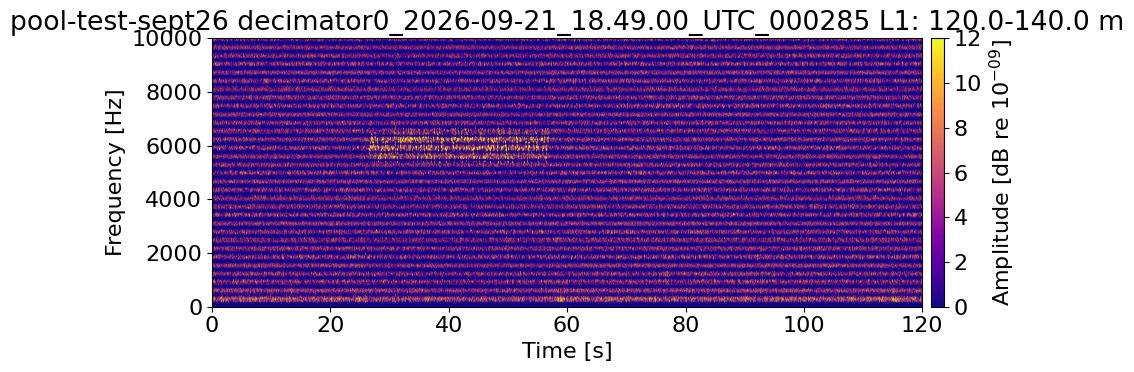

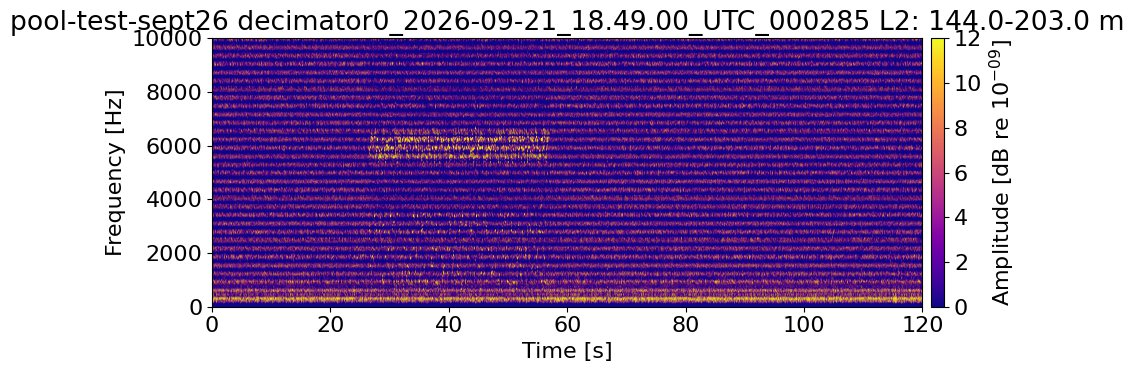

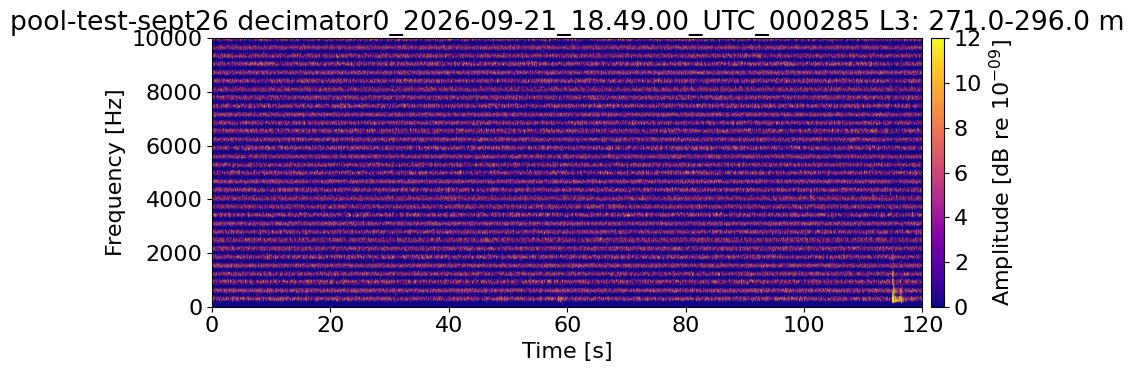

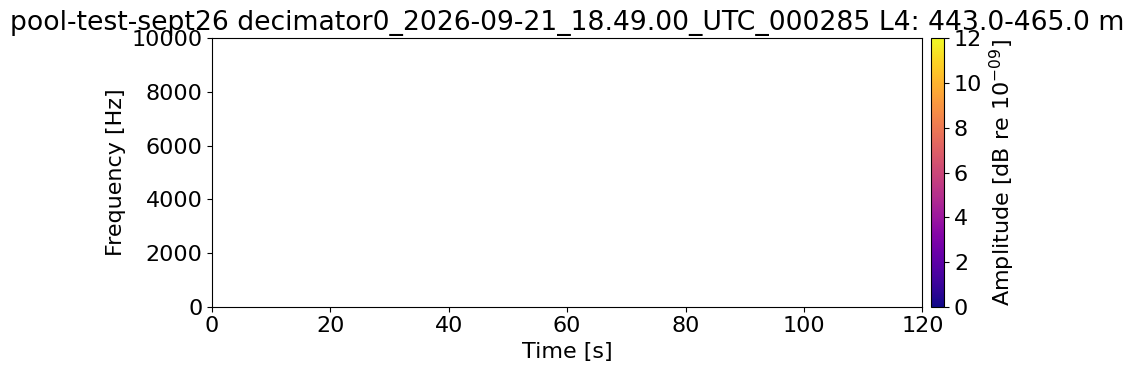

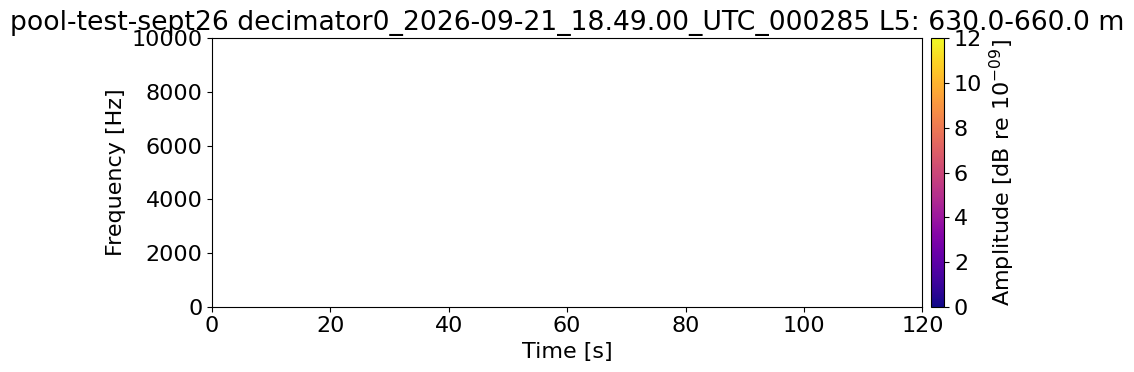

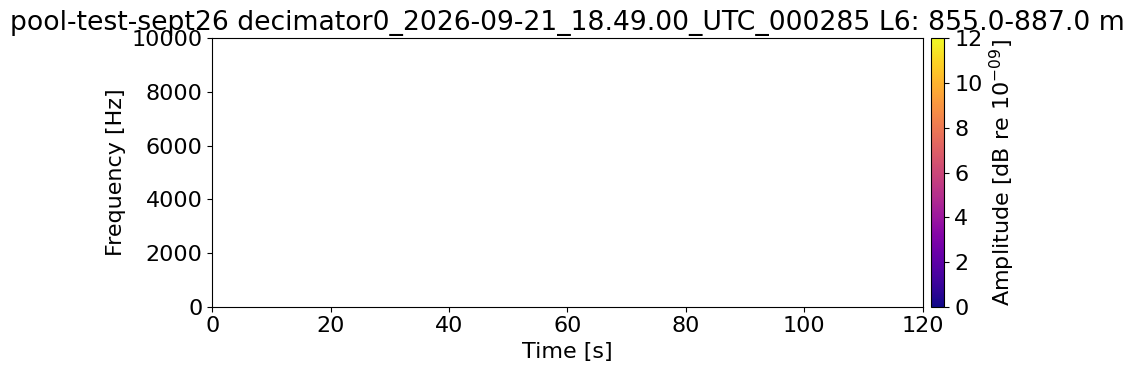

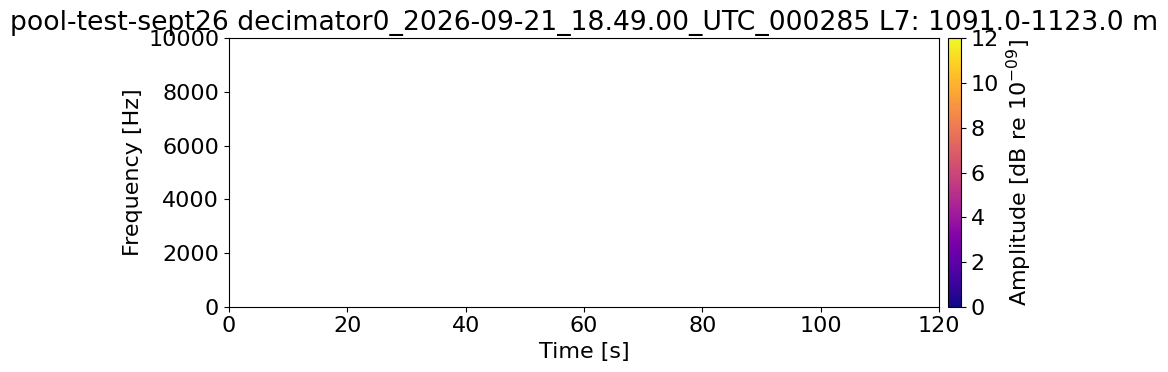

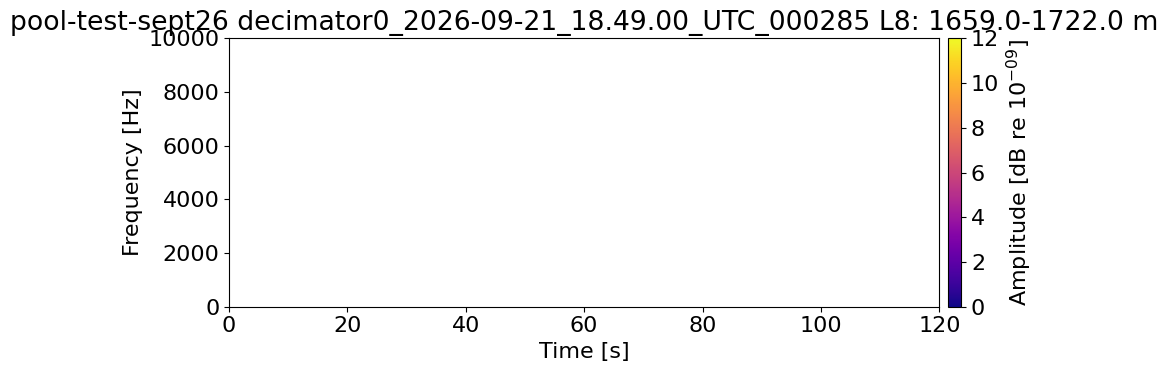

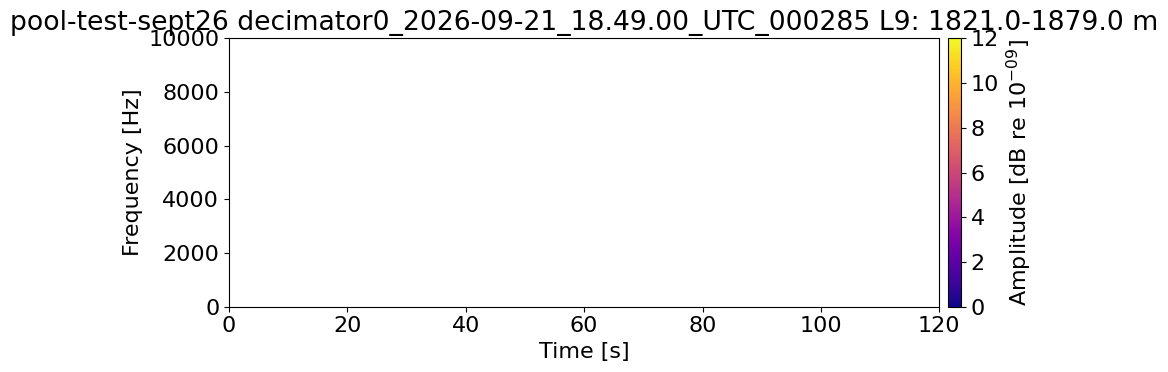

In [21]:
plt.rcParams.update({'font.size': 16})



nperseg = 512
noverlap = int(nperseg * 0.8)
fs_ds = fs

for i in range(1, 10):

    stacked_signal = loop_stacks[f"loop{i}"]

    # use fiber-2 geometry only for labeling (optional)
    start_m, end_m = loops[i-1]

    # STFT
    f, t_stft, Zxx = stft(
        stacked_signal,
        fs=fs_ds,
        nperseg=nperseg,
        noverlap=noverlap
    )

    Sxx_dB = 20 * np.log10(np.abs(Zxx) + 1e-12)
    # Sxx_dB_med = Sxx_dB - np.median(Sxx_dB, axis=1, keepdims=True)
    Sxx_dB_med = Sxx_dB - np.median(Sxx_dB, axis=0, keepdims=True)


    plt.figure(figsize=(10, 4))
    plt.pcolormesh(
        t_stft, f, Sxx_dB_med,
        shading='gouraud',
        cmap='plasma',
        vmin=0, vmax=12
    )

    plt.ylabel('Frequency [Hz]')
    plt.xlabel('Time [s]')

    title = (
        f'{fdir.strip("/").split("/")[-1]} '
        f'{flist[0].replace("decimator_", "").replace(".h5", "")} '
        f'L{i}: {start_m:.1f}-{end_m:.1f} m'
    )

    plt.title(title)
    plt.colorbar(label=r'Amplitude [dB re $10^{-09}$]', pad=0.01)

    plt.tight_layout()
    plt.show()

    plt.close()

In [ ]:
# Loop 1 - channels [1213:1219] - distance range: 3869.5 m to 3888.6 m
# Loop 2 - channels [1193:1211] - distance range: 3805.7 m to 3863.1 m
# Loop 3 - channels [1164:1172] - distance range: 3713.2 m to 3738.7 m
# Loop 4 - channels [1050:1059] - distance range: 3349.5 m to 3378.2 m
# Loop 5 - channels [978:988] - distance range: 3119.8 m to 3151.7 m
# Loop 6 - channels [904:914] - distance range: 2883.8 m to 2915.7 m
# Loop 7 - channels [717:736] - distance range: 2287.2 m to 2347.8 m
# Loop 8 - channels [667:686] - distance range: 2127.7 m to 2188.3 m

(array([8.58739514e-16, 2.16054935e-15, 4.31527196e-15, 9.75952744e-15,
        8.07842085e-14, 7.26102964e-13, 1.10663365e-11, 1.09636240e-10,
        8.39754828e-10, 2.57351466e-09, 9.35851017e-09, 3.13877236e-08,
        2.16157112e-08, 2.22125586e-08, 3.22451504e-08, 3.33789166e-08,
        3.29686941e-08, 4.11061892e-08, 3.08389792e-08, 2.61031631e-08,
        1.57917205e-08, 1.01355542e-08, 5.94931449e-09, 4.51275651e-09,
        3.89975233e-09, 5.04278406e-09, 6.41769942e-09, 1.15392452e-08,
        1.34157125e-08, 1.79697790e-08, 2.11424264e-08, 2.37797434e-08,
        2.50055688e-08, 2.44913830e-08, 2.18246229e-08, 1.87327913e-08,
        1.23749274e-08, 8.14171957e-09, 4.56649258e-09, 2.49090029e-09,
        1.75397899e-09, 2.58709481e-09, 4.61141723e-09, 9.07769345e-09,
        1.22415400e-08, 1.65225910e-08, 2.04689740e-08, 2.32587635e-08,
        2.36112647e-08, 2.23873662e-08, 2.04247560e-08, 1.74010211e-08,
        1.22387498e-08, 7.78287113e-09, 4.09184306e-09, 1.881895

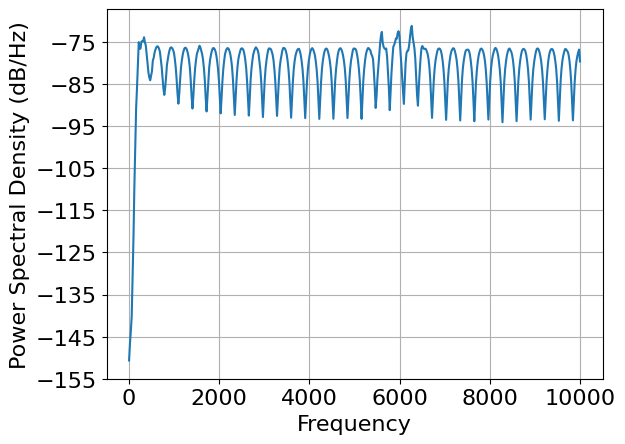

In [ ]:
plt.psd(loop_stacks["loop1"], NFFT=1024, Fs=fs)


## plot spec of single channel or specified range

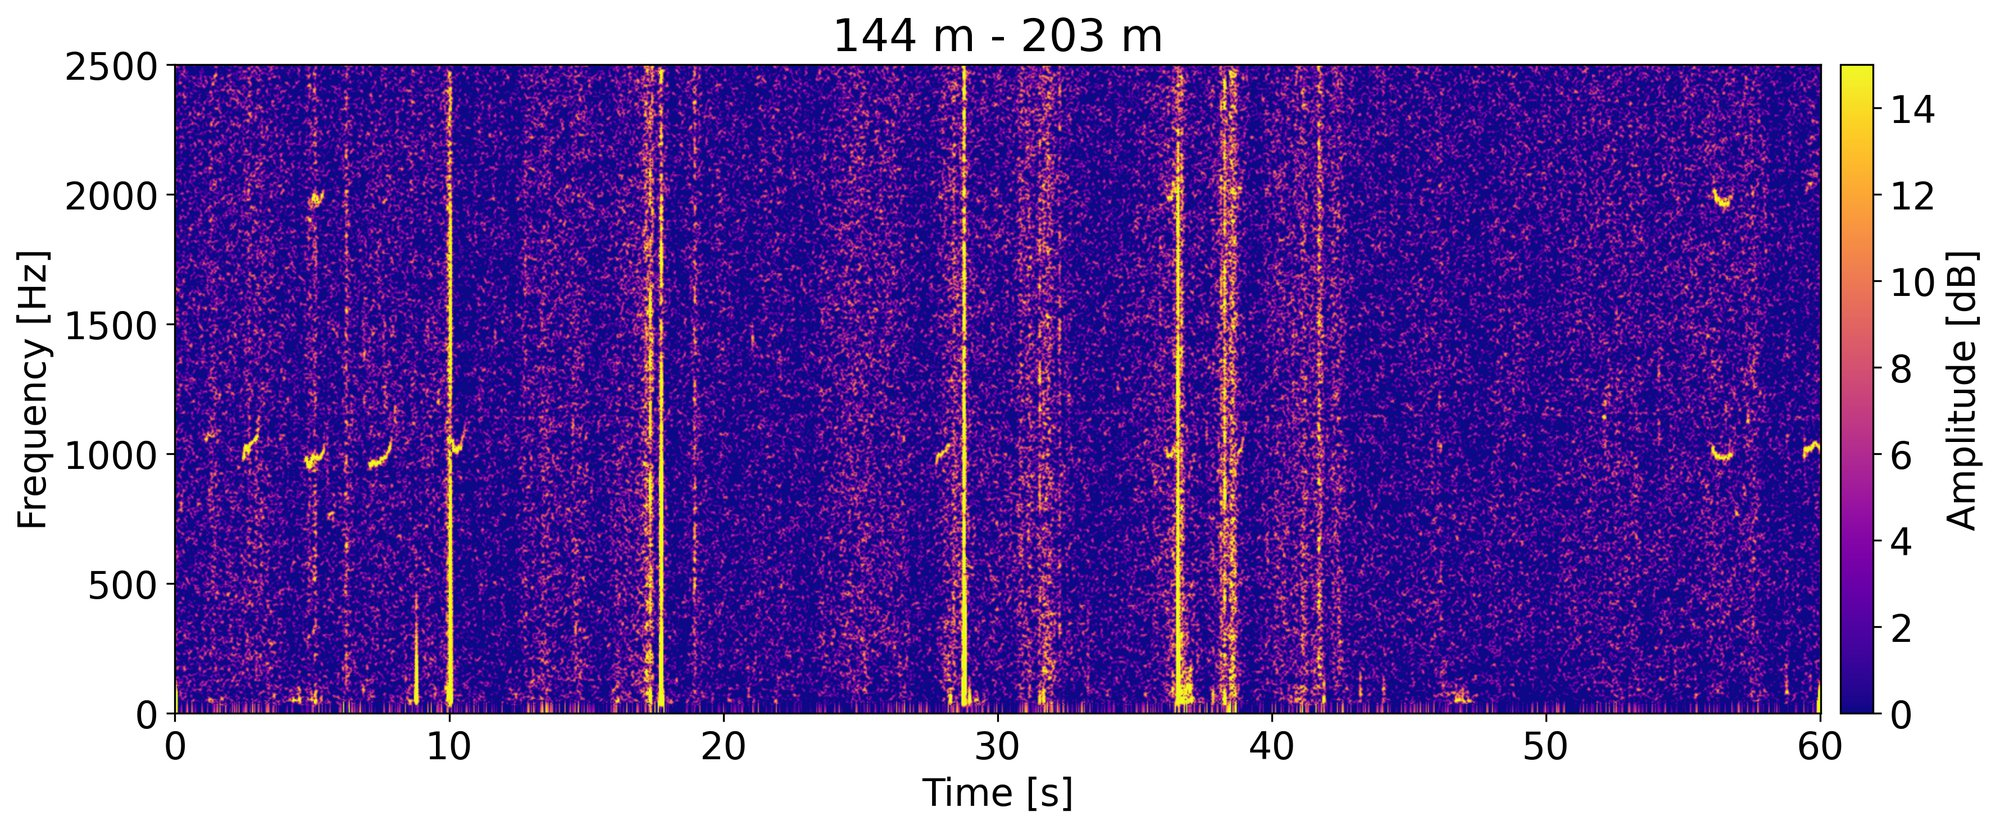

In [ ]:

# ch_m = 380  

# # convert meters
# ch = int(ch_m / dx)

# # safety check
# if ch < 0 or ch >= data.shape[1]:
#     raise ValueError(f"Channel {ch} out of range (max {data.shape[1]})")

# signal_ch = data[:, ch]

#(271, 296)

start_m = 144
end_m = 203
# start_m = 375
# end_m = 415
data_subset = data[:, int(start_m/dx):int(end_m/dx)]

stacked = np.mean(data_subset, axis=1)


nperseg = 1024
noverlap = int(nperseg * 0.8)

# # STFT
f, t_spec, Zxx = stft(stacked, fs=fs, nperseg=nperseg, noverlap=noverlap)
#f, t_spec, Zxx = median_baseline_normalization(signal_ch, fs=fs, nperseg=nperseg, noverlap=noverlap)

# dB scaling
Sxx_dB = 20 * np.log10(np.abs(Zxx) + 1e-12)

Sxx_dB_med = Sxx_dB - np.median(Sxx_dB, axis=1, keepdims=True)
# Sxx_dB_med = Sxx_dB - np.median(Sxx_dB, axis=0, keepdims=True)

plt.figure(figsize=(15, 5), dpi=300)

pcm = plt.pcolormesh(
    t_spec, f, Sxx_dB_med,
    shading='gouraud',
    cmap='plasma',
    vmin=0,
    vmax=15
)

# plt.colorbar(pcm, label='Amplitude [dB re $10^{-09}$]', pad=0.01)

plt.colorbar(pcm, label='Amplitude [dB]', pad=0.01)

plt.ylabel('Frequency [Hz]')
plt.xlabel('Time [s]')

# plt.title(
#     f"{ch_m} m (channel {ch})"
#     f"{fdir.strip('/').split('/')[-1]} {flist[0]}"
# )

plt.title(
    f"{start_m} m - {end_m} m"
    # f"{fdir.strip('/').split('/')[-1]} {flist[0]}"
)

# plt.xlim(0, 20)
plt.show()

In [ ]:
# # Parameters
# start_range = 300
# end_range = 800
# window_m = 10   # stack width (meters)

# nperseg = 512
# noverlap = int(nperseg * 0.8)

# plt.rcParams.update({'font.size': 20})

# for start_m in np.arange(start_range, end_range, window_m):

#     end_m = start_m + window_m

#     # Convert meters → channel indices
#     ch_start = int(start_m / dx)
#     ch_end   = int(end_m / dx)

#     # Extract and stack
#     data_subset = data[:, ch_start:ch_end]
#     stacked = np.mean(data_subset, axis=1)

#     # STFT
#     f, t_spec, Zxx = stft(
#         stacked,
#         fs=fs,
#         nperseg=nperseg,
#         noverlap=noverlap
#     )

#     # Convert to dB
#     Sxx_dB = 20 * np.log10(np.abs(Zxx) + 1e-12)

#     # Plot
#     plt.figure(figsize=(15, 5), dpi=300)

#     pcm = plt.pcolormesh(
#         t_spec,
#         f,
#         Sxx_dB,
#         shading='gouraud',
#         cmap='plasma',
#         vmin=-80,
#         vmax=-65
#     )

#     plt.colorbar(pcm, label=r"Strain (dB re $10^{-9}$)", pad=0.01)

#     plt.ylabel('Frequency [Hz]')
#     plt.xlabel('Time [s]')

#     plt.title(
#         f'{fdir.strip("/").split("/")[-1]} '
#         f'{flist[0].replace("decimator_", "").replace(".h5", "")} '
#         f'{start_m:.0f}–{end_m:.0f} m'
#     )

#     plt.tight_layout()
#     plt.show()

#### Reassigned spectrogram


In [ ]:

# n_fft = 1024
# # amin = 1e-10
# # n_fft = 64
# # sr = 4000
# # y = 1e-3 * librosa.clicks(times=[0.3], sr=sr, click_duration=1.0,
# #                           click_freq=1200.0, length=8000) +\
# #     1e-3 * librosa.clicks(times=[1.5], sr=sr, click_duration=0.5,
# #                           click_freq=400.0, length=8000) +\
# #     1e-3 * librosa.chirp(fmin=200, fmax=1600, sr=sr, duration=2.0) +\
# #     1e-6 * np.random.randn(2*sr)
# freqs, times, mags = librosa.reassigned_spectrogram(y=stacked, sr=fs,
#                                                     n_fft=n_fft)
# mags_db = librosa.amplitude_to_db(mags, ref=np.max)

In [ ]:
# figsize = (20, 16)

# img = librosa.display.specshow(mags_db, x_axis="s", y_axis="linear", sr=fs,
#                          hop_length=n_fft//10, ax=ax[0])
# plt.pcolormesh(title="Spectrogram", xlabel=None)

# plt.label_outer()
# plt.scatter(times, freqs, c=mags_db, cmap="magma", alpha=0.1, s=8, vmin=-80, vmax=-30)
# plt.set_title("Reassigned spectrogram")
# plt.xlim(0,30)
# plt.set_ylim(100, 2500)
# fig.colorbar(img, ax=ax, format="%+2.f dB")

In [ ]:
# figsize = (20, 16)
# fig, ax = plt.subplots(nrows=2, sharex=True, sharey=True, figsize=figsize)
# img = librosa.display.specshow(mags_db, x_axis="s", y_axis="linear", sr=fs,
#                          hop_length=n_fft//10, ax=ax[0])
# ax[0].set(title="Spectrogram", xlabel=None)
# ax[0].set_xlim(0,30)
# ax[0].label_outer()
# ax[1].scatter(times, freqs, c=mags_db, cmap="magma", alpha=0.1, s=8, vmin=-80, vmax=-30)
# ax[1].set_title("Reassigned spectrogram")
# ax[1].set_xlim(0,30)
# ax[1].set_ylim(100, 2500)
# fig.colorbar(img, ax=ax, format="%+2.f dB")


### Plot spectrograms of multiple channels

In [ ]:


# plt.rcParams.update({'font.size': 16})

# nperseg = 512
# noverlap = nperseg * 0.8
# fs_ds = fs

# # ----------------------------
# # Loop through ALL loops
# for i, ((start_m, end_m), loop_key) in enumerate(zip(loops, loop_stacks.keys()), 1):

#     signal_loop = loop_stacks[loop_key]

#     # Compute STFT
#     f, t_stft, Zxx = stft(signal_loop, fs=fs_ds,
#                           nperseg=nperseg, noverlap=noverlap)

#     # Convert to dB
#     Sxx_dB = 20 * np.log10(np.abs(Zxx) + 1e-12)

#     # Plot
#     plt.figure(figsize=(12, 4))
#     plt.pcolormesh(t_stft, f, Sxx_dB,
#                    shading='gouraud', cmap='plasma',
#                    vmin=-80, vmax=-55)

#     plt.ylabel('Frequency [Hz]')
#     plt.xlabel('Time [s]')
#     plt.title(f'Loop {i}: {start_m}-{end_m} m')

#     plt.colorbar(label=r'Amplitude [dB re $10^{-09}$]')
#     # plt.ylim(10, 2400)
#     # plt.xlim(0, 60)

#     plt.tight_layout()

In [ ]:

# L1 = (114, 139)
# L2 = (144, 203)
# L3 = (271, 296)
# L4 = (440, 504)
# L5 = (855, 887)
# L6 = (1091, 1123)
# L7 = (1659, 1722)
# L8 = (1821, 1879)

# # for range in L1, L2, L3, L4, L5, L6, L7, L8:
# #     range_idx = (int(range[0]/dx), int(range[1]/dx))
# #     print(f"Range {range} m: channels {range_idx}, Noise power: {np.mean(noise_file[:,range_idx[0]:range_idx[1]]**2)}")

# loops = [L1, L2, L3, L4, L5, L6, L7, L8]

# loop_channels = [
#     (int(L[0] / dx), int(L[1] / dx))
#     for L in loops
# ]

# for L, (c0, c1) in zip(loops, loop_channels):
#     print(
#         f"Range {L} m: channels {c0}:{c1}, "
#         f"channel power = {np.mean(data[:, c0:c1]**2):.2e}"
#     )




In [ ]:

# #     # Save figure
# # fname = os.path.join(results_dir, f'{ch_dist} {fdir} {flist}.png')
# plt.savefig(fname, dpi=150)
# plt.close()  # close to free memory

    


## Figure for manuscript

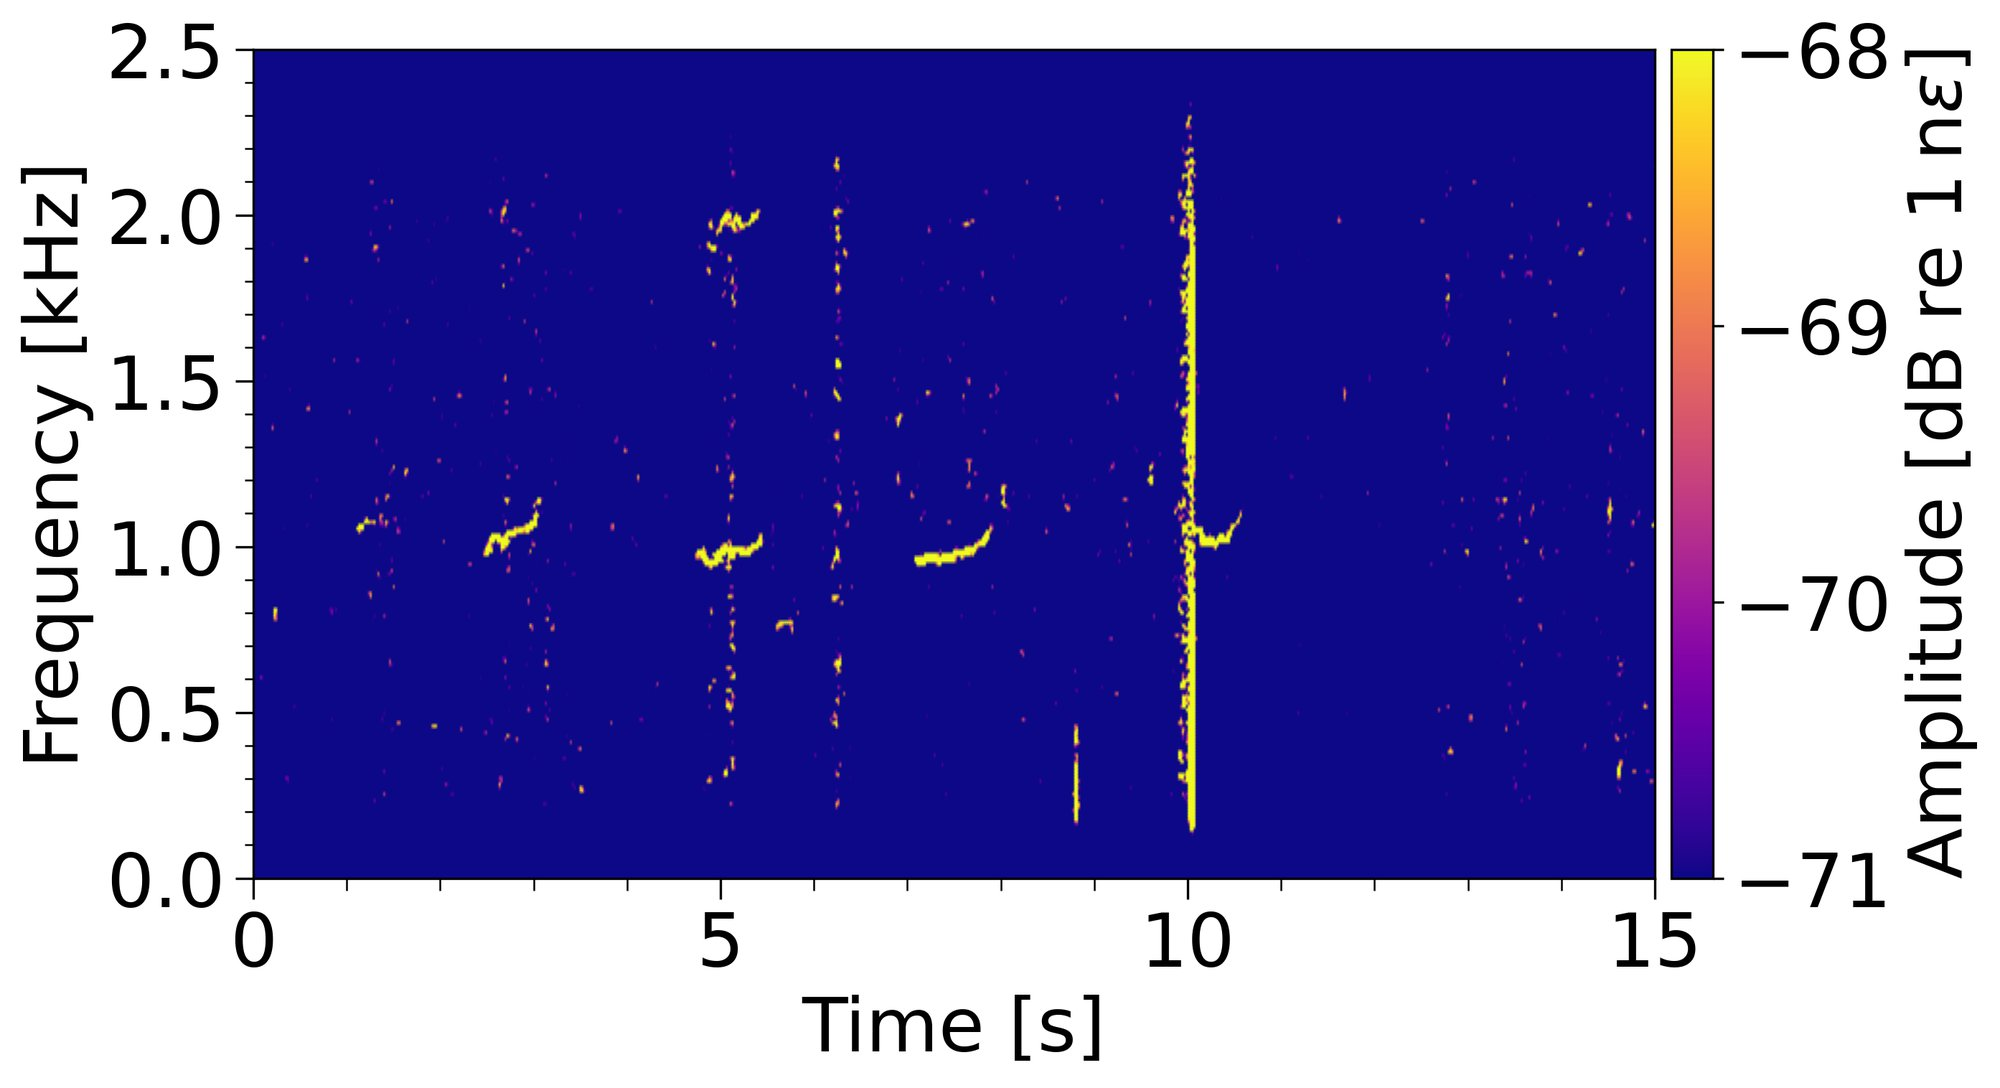

In [ ]:
loop_id = 2  # choose 1–8

stacked = loop_stacks[f"loop{loop_id}"]

# start_m = 485
# end_m = 505
# # start_m = 375
# # end_m = 415
# data_subset = data[:, int(start_m/dx):int(end_m/dx)]

# stacked = np.mean(data_subset, axis=1)

# channel = data[:, int(135/dx)]


# ch_m = 390

# # convert meters
# ch = int(ch_m / dx)

# # safety check
# if ch < 0 or ch >= data.shape[1]:
#     raise ValueError(f"Channel {ch} out of range (max {data.shape[1]})")

# channel = data[:, ch]

nperseg = 512
noverlap = int(nperseg * 0.8)

f, t_spec, Zxx = stft(
    stacked,
    fs=fs,
    nperseg=nperseg,
    noverlap=noverlap
)


t_start = 0 ##jpod
t_end = 15

# #biggs
# t_start = 12
# t_end = 27

# #humpback 1
# t_start = 45
# t_end = 60

#humpback 2
# t_start = 2
# t_end = 17

# #humpback 1
# t_start = 0
# t_end = 60



# STFT time is relative to input signal → assume signal starts at t=0
t_abs = t_spec


mask = (t_abs >= t_start) & (t_abs <= t_end)

t_plot = t_abs[mask] - t_start
Z_plot = Zxx[:, mask]


Sxx_dB = 20 * np.log10(np.abs(Z_plot) + 1e-12)

plt.rcParams.update({'font.size': 25})
plt.figure(figsize=(10, 5), dpi=300)

pcm = plt.pcolormesh(
    t_plot,
    f,
    Sxx_dB,
    shading='gouraud',
    cmap='plasma',
    vmin=-71,
    vmax=-68
)

#plt.colorbar(pcm, label='Amplitude [dB re $10^{-09}$]', pad=0.01) #\text{dB re } 1\,\text{n}\epsilon
plt.colorbar(pcm, label=r'Amplitude [dB re $1\,\mathrm{n}\epsilon$]', pad=0.01)

plt.xlim(0, t_end - t_start)

xt = np.arange(0, (t_end - t_start) + 1, 5)
plt.xticks(xt)

# ax = plt.gca()
# ax.set_xticks(np.arange(0, (t_end - t_start) + 1, 1), minor=True)
# ax.tick_params(axis='x', which='minor', length=4)
# ax.tick_params(axis='x', which='major', length=7)


# plt.yticks(np.arange(0, 2501, 500))
# ax.set_yticks(np.arange(0, 2501, 100), minor=True)
# ax.tick_params(axis='y', which='minor', length=3)
# ax.tick_params(axis='y', which='major', length=6)


# plt.ylabel('Frequency [Hz]')
# plt.xlabel('Time [s]')
    # Relative x-axis limits


ax = plt.gca()
ax.set_xticks(np.arange(0, (t_end - t_start) + 1, 1), minor=True)
ax.tick_params(axis='x', which='minor', length=4)
ax.tick_params(axis='x', which='major', length=7)

    # Frequency axis limits and ticks
    # y_max = highcut if 'highcut' in locals() else 2500
y_max = 2500
plt.ylim(0, 2500)
    # plt.yticks(np.arange(0, y_max + 1, 500))
yticks = np.arange(0, y_max + 1, 500)
plt.yticks(yticks, labels=yticks / 1000)  # convert to kHz labels
    
ax.set_yticks(np.arange(0, y_max + 1, 100), minor=True)
ax.tick_params(axis='y', which='minor', length=3)
ax.tick_params(axis='y', which='major', length=6)

plt.ylabel('Frequency [kHz]')
plt.xlabel('Time [s]')
    #plt.title(f"Window {t_start_select}-{t_end_select}s | {node_to_plot if 'node_to_plot' in locals() else 'OrcaSound'}")


#plt.title(f"Loop {loop_id} | Window {t_start}-{t_end} ")

plt.show()

### Play audio

In [ ]:

# sig = stacked
# #signal = data[:, 56]

# # # Make sure it's 1D and normalized
# # if data.ndim == 2:
# #     signal = stacked
# # else:
# #     signal = data

# # Bandpass BEFORE normalization/resampling
# b, a = signal.butter(6, [750, 1500], btype='bandpass', fs=fs)
# sig = signal.filtfilt(b, a, sig, axis=0)


In [ ]:
# import numpy as np
# from scipy.signal import resample
# from IPython.display import Audio

# # Normalize
# sig = sig / (np.max(np.abs(sig)) + 1e-12)
# sig = sig.astype(np.float32)

# # Sampling rates
# fs_original = fs
# fs_audio = 5000

# # Select time window
# start_sec, end_sec = 10, 15
# start_idx = int(start_sec * fs_original)
# end_idx = int(end_sec * fs_original)

# segment = sig[start_idx:end_idx]   # ✅ FIXED

# # Resample
# num_samples = int(len(segment) * fs_audio / fs_original)
# resampled = resample(segment, num_samples)

# # Gain
# gain_db = 100
# gain = 10 ** (gain_db / 20)

# resampled = resampled * gain
# resampled = np.clip(resampled, -1, 1)

# # Play audio
# Audio(resampled, rate=fs_audio)

### Play audio

In [ ]:
# sig = stacked
# #signal = data[:, 56]

# # # Make sure it's 1D and normalized
# # if data.ndim == 2:
# #     signal = stacked
# # else:
# #     signal = data
sig = loop2

# --- Configuration ---
start_sec, end_sec = 0, 60       # Time window (seconds)
lowcut, highcut = 10, 500       # Bandpass range (Hz)
denoise_method = 'median_baseline' # Options: 'median_baseline', 'bandpass_only', 'none'
gain_db = 0                    # Audio gain

# 1. Bandpass Filter
if lowcut > 0 and highcut > 0:
    sig_proc = bandpass_filter(sig, fs, lowcut, highcut)
else:
    sig_proc = sig.copy()

# 2. Denoising
if denoise_method == 'median_baseline':
    sig_proc, f_spec, t_spec, _ = median_baseline_normalization(sig_proc, fs, nperseg=512, noverlap=256)
elif denoise_method == 'bandpass_only' or denoise_method == 'none':
    pass
else:
    print(f"Unknown denoise method: {denoise_method}. Using bandpassed signal.")

# 3. Select segment to convert to audio
start_idx = int(start_sec * fs)
end_idx   = int(end_sec   * fs)
segment = sig_proc[start_idx:end_idx]

# 4. Resample (if needed) and Play
fs_audio = fs
num_samples = int(len(segment) * fs_audio / fs)
resampled = resample(segment, num_samples)

# Apply gain and clip
gain = 10 ** (gain_db / 20)
resampled = np.clip(resampled * gain, -1, 1)

Audio(resampled, rate=fs_audio)



### Convert to .wav and save

In [ ]:
from scipy.io.wavfile import write
from IPython.display import FileLink
# --- Save to WAV file ---
# Convert float [-1,1] to int16 for WAV


# Ensure output folder exists
os.makedirs(results_dir, exist_ok=True)

# Define full output path
output_file = os.path.join(results_dir, "humpback-DAS.wav")

# Convert float [-1,1] to int16 for WAV
resampled_int16 = (resampled * 32767).astype(np.int16)

# Save WAV file (ensure fs is integer)
write(output_file, int(fs_audio), resampled_int16)

print(f"Audio saved to: {output_file}")
FileLink(output_file)

Audio saved to: /home/sam/DAS4Orcas/results/july-2026-test/2026-07-08/humpback-DAS.wav


/home/sam/DAS4Orcas/results/july-2026-test/2026-07-08/humpback-DAS.wav

### Plot spectrograms of multiple channels and save

In [ ]:
# start_dist = 100
# end_dist = 2000
# channel_range = np.arange(start_dist, end_dist + dx, dx)  # meters
# ch_indices = [int(np.round(d / dx)) for d in channel_range]

# nperseg = 1024
# noverlap = 556
# fs_ds = fs  # adjust if downsampling
# results_dir = os.path.expanduser(f'~/results/{flist}')
# os.makedirs(results_dir, exist_ok=True)

# # Extract a clean base name (remove extension if it has one)
# base_name = os.path.splitext(os.path.basename(flist))[0]

# # --- Loop through channels in range ---
# for ch_idx, ch_dist in zip(ch_indices, channel_range):
#     signal_ch = data[:, ch_idx]

#     # Compute STFT
#     f, t_stft, Zxx = stft(signal_ch, fs=fs_ds, nperseg=nperseg, noverlap=noverlap)

#     # Convert to dB
#     Sxx_dB = 20 * np.log10(np.abs(Zxx) + 1e-12)

#     # --- Plot ---
#     plt.figure(figsize=(12, 4))
#     plt.pcolormesh(t_stft, f, Sxx_dB, shading='gouraud', cmap='viridis')
#     plt.ylabel('Frequency [Hz]')
#     plt.xlabel('Time [s]')
#     plt.title(f'Channel {ch_idx} ({ch_dist:.1f} m)')
#     plt.colorbar(label='Amplitude [dB re $10^{-9}$]')
#     plt.ylim(0, 2000)
#     plt.xlim(0, 60)
#     plt.tight_layout()

#     # --- Save figure ---
#     plot_filename = f"{base_name}_spectrogram_ch{ch_dist:.1f}.png"
#     filepath = os.path.join(results_dir, plot_filename)
#     plt.savefig(filepath, dpi=300, bbox_inches='tight')
#     plt.close()

# print(f"Saved {len(ch_indices)} spectrograms to: {results_dir}")


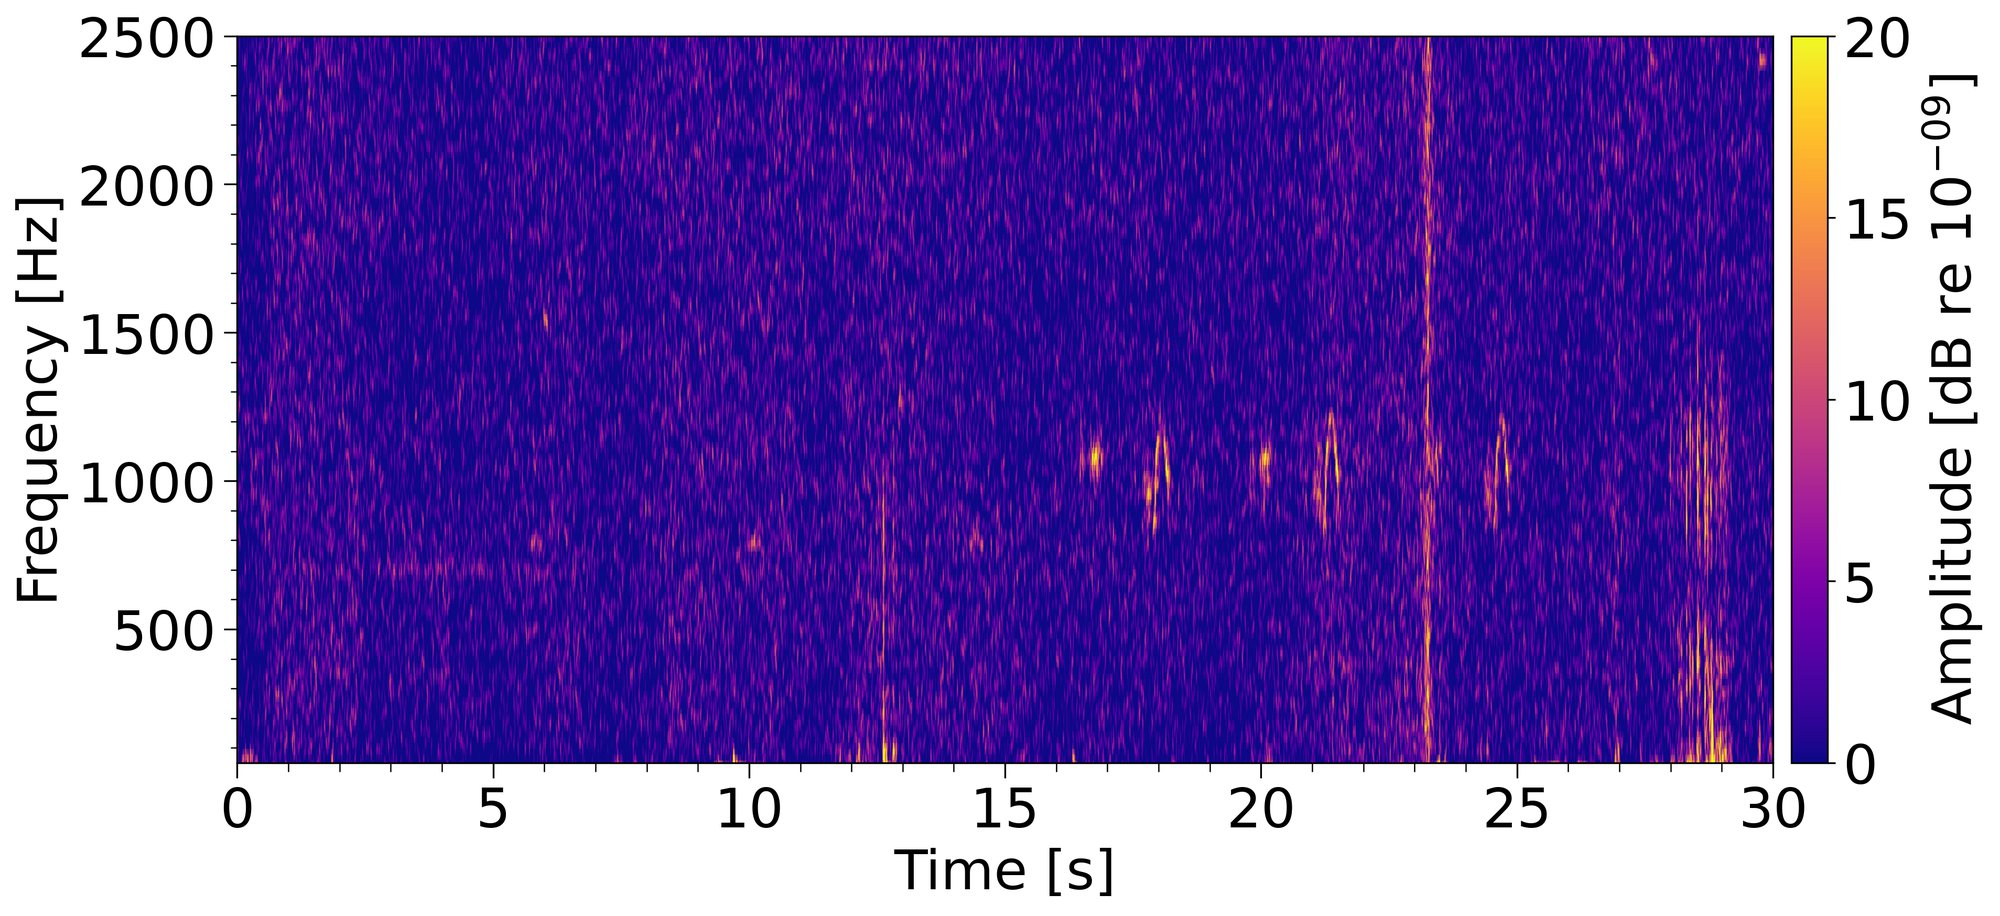

In [ ]:
nperseg=512
noverlap = nperseg * 0.9

f, t_spec, Sxx_dB_stacked = median_subtraction_spectrogram(
    stacked, fs, nperseg=nperseg, noverlap=noverlap
)

# Subtract median as in calc-TFSNR-haro-strait.ipynb
Sxx_dB_stacked -= np.nanmedian(Sxx_dB_stacked)

plt.rcParams.update({'font.size': 25})
plt.figure(figsize=(15,6), dpi = 300)

# Spectrogram
pcm = plt.pcolormesh(t_spec, f, Sxx_dB_stacked, shading='gouraud', cmap='plasma', vmin = 0, vmax=20)
plt.colorbar(pcm, label='Amplitude [dB re $10^{-09}$]', pad=0.01)

##Major ticks every 5 sec
plt.xticks(np.arange(0, 31, 5))

# Minor ticks every 1 sec
ax = plt.gca()
ax.set_xticks(np.arange(0, 31, 1), minor=True)
ax.tick_params(axis='x', which='minor', length=4)
ax.tick_params(axis='x', which='major', length=7)

##Major ticks (with labels) every 500 Hz
plt.yticks(np.arange(0, 2501, 500))

# Minor ticks (no labels) every 100 Hz
ax = plt.gca()
ax.set_yticks(np.arange(0, 2501, 100), minor=True)

ax.tick_params(axis='y', which='minor', length=3)
ax.tick_params(axis='y', which='major', length=6)

plt.xlim(0,30)
plt.ylim(50, 2500)

plt.ylabel('Frequency [Hz]')
plt.xlabel('Time [s]')
plt.show()


### Plot Multiple Spectrograms for a Range of Individual Channels

In [ ]:
# chan_range = range(130, 150)  # Set your channel range here
# n_chans = len(chan_range)

# # Spectrogram parameters
# nperseg = 1024
# noverlap = nperseg * 0.5
# vmin, vmax = 0, 25

# fig, axes = plt.subplots(n_chans, 1, figsize=(15, 5 * n_chans), sharex=True, dpi=150)
# if n_chans == 1:
#     axes = [axes]

# for i, chan in enumerate(chan_range):
#     trace = data[:, chan]
#     f, t_spec, Sxx_dB = median_subtraction_spectrogram(trace, fs, nperseg=nperseg, noverlap=noverlap)
    
#     ax = axes[i]
#     pcm = ax.pcolormesh(t_spec, f, Sxx_dB, shading='gouraud', cmap='magma', vmin=vmin, vmax=vmax)
#     ax.set_title(f"Channel {chan}")
#     ax.set_ylabel("Frequency [Hz]")
#     ax.set_ylim(50, 2500)  # Adjust as needed
#     plt.colorbar(pcm, ax=ax, label=r'Amplitude [dB re $1\,\mathrm{n}\epsilon$]', pad=0.01)

# axes[-1].set_xlabel("Time [s]")
# plt.tight_layout()
# plt.show()